# Pontin et al. (2026): optical squeezing mediated by two ground-state mechanical modes

A. Pontin, Q. Deplano, F. Marino and F. Marin,
*Optical squeezing mediated by levitated oscillators at their quantum ground state*,
Phys. Rev. A **114**, 053704 (2026), [doi:10.1103/hms3-yb2h](https://doi.org/10.1103/hms3-yb2h)
(read as arXiv:2604.26790v1). The system and its parameters are those of
Q. Deplano, A. Pontin, A. Ranfagni, F. Marino and F. Marin, *High purity two-dimensional levitated
mechanical oscillator*, Nat. Commun. **16**, 4215 (2025), [doi:10.1038/s41467-025-59213-3](https://doi.org/10.1038/s41467-025-59213-3).

A 100 nm silica sphere in a 1064 nm tweezer sits at a node of a sideband-resolved cavity
($\kappa/2\pi$ = 57 kHz). Coherent scattering couples both transverse modes ($\Omega/2\pi \approx$ 122 and
109 kHz) strongly to the cavity mode, cools them to $n_x$ = 0.55 and $n_y$ = 0.74, and the
optomechanical correlations push some output quadratures below shot noise. The paper measures the
full 2 × 2 spectral covariance matrix of the output quadratures by heterodyne detection and maps the
quadrature spectrum against detection phase and frequency. This notebook builds the system in
levisim from the published couplings and heating rates and reproduces

1. the occupations and the mechanical covariance matrix (Nat. Commun. Eq. (4)), and the stability of the system,
2. the heating budget from the stated pressure and power (levisim's gas and photon-recoil heating),
3. the spectral covariance matrix of the output light (Fig. 2), including the phase-noise variance $\sigma_\theta^2$,
4. the map of the quadrature spectrum against phase and frequency (Fig. 3) and its sub-shot-noise regions,
5. the optimal quadrature spectrum (Fig. 4) and the squeezing at higher detection efficiency.

The quadrature covariance matrix, the noise models, the detection efficiency, the phase-noise average
and the optimal spectrum come from `levisim.multiphysics.quadrature_squeezing`.

Runtime: about 2 s of computation after the imports.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| bare frequencies $(\Omega_X, \Omega_Y)/2\pi$ | 122.17, 109.37 kHz | Nat. Commun. Table 1 (fit) |
| couplings $(g_x, g_y)/2\pi$ | 14.13 ± 0.22, 10.37 ± 0.16 kHz | PRA Table I = Nat. Commun. Table 1 |
| heating (decoherence) rates $(\Gamma_x, \Gamma_y)/2\pi$ | 4.03 ± 0.32, 3.05 ± 0.26 kHz | PRA Table I |
| cavity linewidth $\kappa/2\pi$ (FWHM), FSR | 57 kHz, 3.07 GHz | PRA text; Nat. Commun. |
| detuning $\Delta/2\pi$ | −111 kHz (red) | Nat. Commun. Fig. 2 (the PRA analyses "the same experimental data" and only says $-\Delta \simeq \Omega_i$) |
| detection efficiency | $\eta$ = 0.32, × ½ for the heterodyne measurement of both quadratures → 0.16 | PRA Results and Appendix A |
| phase-noise variance | $\sigma_\theta^2$ = 0.062 rad² (fitted in the paper) | PRA after Eq. (1) |
| particle, tweezer, pressure | 100 nm silica, 250 mW at 1064 nm, waist < 1 μm, 3 × 10⁻⁸ mbar | Nat. Commun. Results |
| $\Omega_z/2\pi$ | 21.4 kHz (not modelled: the PRA neglects $z$) | Nat. Commun. Results |

**Axes and signs.** The papers' $Y$ is the tweezer polarisation and $X$ is perpendicular to it;
levisim's tweezer is polarised along its $y$ axis, so the paper's $x$, $y$ are levisim's `'x1'`, `'y1'`.
Both papers write $\Delta$ as tweezer minus cavity frequency with red detuning negative, the same sign as
levisim. The output quadratures follow the PRA's Appendix A, $Q = a_\mathrm{out} + a_\mathrm{out}^\dagger$ and
$P = i(a_\mathrm{out}^\dagger - a_\mathrm{out})$; a detection phase $\phi$ selects $Q\cos\phi + P\sin\phi$, which is
levisim's `homodyne_spectrum` at `cavity.θhom` = $-\phi$ (checked below).

**Modelling choices.**

- The system is a toy-parameter `MultiTrap` with the fitted $g_j$ and the fitted *total* heating rates
  $\Gamma_j$ (`paper_tools.toy_multitrap`). The papers do not give the cavity waist or the particle's
  offset from the node, so levisim's first-principles couplings cannot be computed. Photon recoil is
  then already inside $\Gamma_j$. The physical system in the heating-budget section passes
  `photon_recoil` explicitly.
- Heating is a force noise in the papers' model: it diffuses the momentum only (Nat. Commun. Eq. (3)).
  levisim's own bath acts on $b$ and $b^\dagger$, so it diffuses position and momentum equally. Both give the
  same heating rate, but their spectra differ away from the mechanical resonances, where the
  squeezing is. Both are shown; the force-noise model (`noise='force'`) is the papers' model.
- The paper's gas damping is negligible (about $2\pi \times 4 \times 10^{-5}$ Hz at 3 × 10⁻⁸ mbar), and
  so is the $z$ mode.

In [ ]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # paper_tools.py sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import brentq, fsolve, minimize_scalar

from levisim.core.constants import π
from levisim.core.units import kHz, nm, μm, mbar
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics.tweezer import Tweezer
from levisim.physics.bead import Bead
from levisim.physics.trap import Trap
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.covariance import dimension_covariance
from levisim.multiphysics.quadrature_squeezing import (
    output_quadrature_spectra, steady_state_covariance_with_noise, with_detection_efficiency,
    phase_noise_averaged, quadrature_spectrum, optimal_quadrature_spectrum,
)

from paper_tools import toy_multitrap, gas_heating_rate, occupations, mechanical_eigenfrequencies, load_digitised

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
T_START = time.time()

## The system, its stability and its occupations

The gas damping of the toy system is levisim's Epstein damping for the stated particle and pressure
(it only sets the bath through which the fitted heating is imposed). Stability is read from the drift
matrix: every eigenvalue must have a negative real part.

In [ ]:
Ω_X, Ω_Y = 122.17*kHz, 109.37*kHz
G_X, G_Y = 14.13*kHz, 10.37*kHz
Γ_X, Γ_Y = 4.03*kHz, 3.05*kHz
κ_P, Δ_P = 57*kHz, -111*kHz
η_HET = 0.32 / 2          # PRA: η = 0.32, times 1/2 for measuring both quadratures
σθ2_PAPER = 0.062         # rad²
P_GAS = 3e-8*mbar
BEAD = Bead(r=50*nm, Φ=π/2)          # levisim's default silica density, 1850 kg/m³ (not stated)
Ω_DICT = {'x': Ω_X, 'y': Ω_Y, 'z': 21.4*kHz}


def physical_multitrap(tweezer, bead=BEAD, photon_recoil=False):
    # used for the gas damping and, below, the heating budget; the cavity geometry is not stated, so
    # its couplings are not used
    return MultiTrap(tweezers=[tweezer], beads=[bead], trap_kwargs=[dict(override_Ω_dict=Ω_DICT)],
                     Cartesian_axes_per_trap=2, gas_kwargs=dict(P=P_GAS, T=300.0),
                     cavity_kwargs=dict(κ=κ_P, Δ=Δ_P), photon_recoil=photon_recoil)


Γ_GAS_DAMPING = physical_multitrap(Tweezer(Power=0.25, λ=1064*nm, θ=π/4)).dimensions['x1'].Γ


def pontin_multitrap(g_x=G_X, g_y=G_Y, Γ_x=Γ_X, Γ_y=Γ_Y, Δ=Δ_P):
    return toy_multitrap({'x1': Ω_X, 'y1': Ω_Y}, {'x1': g_x, 'y1': g_y}, {'x1': Γ_x, 'y1': Γ_y},
                         Δ=Δ, κ=κ_P, m=BEAD.m, Γ=Γ_GAS_DAMPING, λ=1064*nm)


mtrap = pontin_multitrap()
λ_drift = np.linalg.eigvals(mtrap.drift_matrix)
freqs, widths = mechanical_eigenfrequencies(mtrap)
print(f'gas damping Γ/2π = {Γ_GAS_DAMPING/(2*π):.2e} Hz')
print(f'largest Re(eigenvalue) of the drift matrix: {λ_drift.real.max():.4g} s⁻¹ -> '
      f'{"stable" if λ_drift.real.max() < 0 else "UNSTABLE"} (slowest decay rate/2π = {-λ_drift.real.max()/(2*π)/1e3:.2f} kHz)')
print('mechanical-like normal modes: ' + ', '.join(f'{f/kHz:.2f} kHz (linewidth {w/kHz:.2f} kHz)' for f, w in zip(freqs, widths)))

n_levisim = occupations(mtrap)
V_force = steady_state_covariance_with_noise(mtrap, 'force')
n_force = {label: (V_force[2*k, 2*k] + V_force[2*k + 1, 2*k + 1] - 2) / 4 for k, label in enumerate(['x1', 'y1'], start=1)}
print(f'\n{"":4s} {"paper":>12s} {"levisim bath":>13s} {"force noise":>12s}  (n from (V_XX + V_PP - 2)/4)')
for label, paper in (('x1', '0.55 ± 0.03'), ('y1', '0.74 ± 0.04')):
    print(f'n_{label[0]:3s} {paper:>12s} {n_levisim[label]:13.3f} {n_force[label]:12.3f}')

# Nat. Commun. Eq. (4): (x, p_x, y, p_y) covariance, and n from (2n + 1) = sqrt(<x²><p²>)
V_paper = np.array([[2.13, 0, -0.32, -0.59], [0, 2.07, 0.52, -0.34], [-0.32, 0.52, 2.47, 0], [-0.59, -0.34, 0, 2.48]])
V_mech = dimension_covariance(mtrap, V_force, ['x1', 'y1'])
np.set_printoptions(precision=2, suppress=True)
print('\nmechanical covariance, force noise (Nat. Commun. Eq. (4) in brackets):')
for row, prow in zip(V_mech, V_paper):
    print('  ' + '  '.join(f'{v:6.2f} ({p:5.2f})' for v, p in zip(row, prow)))
print(f'max |difference| = {np.abs(V_mech - V_paper).max():.3f}')
for k, label in enumerate(['x', 'y']):
    print(f'n_{label} from sqrt(<x²><p²>): {(np.sqrt(V_mech[2*k, 2*k]*V_mech[2*k+1, 2*k+1]) - 1)/2:.3f}')
print(f'purity 1/sqrt(det V_M) = {1/np.sqrt(np.linalg.det(V_mech)):.3f} (Nat. Commun.: 0.209 ± 0.013)')

gas damping Γ/2π = 3.91e-05 Hz
largest Re(eigenvalue) of the drift matrix: -1.918e+04 s⁻¹ -> stable (slowest decay rate/2π = 3.05 kHz)
mechanical-like normal modes: 111.99 kHz (linewidth 6.11 kHz), 125.83 kHz (linewidth 15.62 kHz)

            paper  levisim bath  force noise  (n from (V_XX + V_PP - 2)/4)
n_x    0.55 ± 0.03         0.553        0.551
n_y    0.74 ± 0.04         0.733        0.738

mechanical covariance, force noise (Nat. Commun. Eq. (4) in brackets):
    2.13 ( 2.13)    0.00 ( 0.00)   -0.32 (-0.32)   -0.59 (-0.59)
    0.00 ( 0.00)    2.07 ( 2.07)    0.53 ( 0.52)   -0.34 (-0.34)
   -0.32 (-0.32)    0.53 ( 0.52)    2.47 ( 2.47)    0.00 ( 0.00)
   -0.59 (-0.59)   -0.34 (-0.34)    0.00 ( 0.00)    2.48 ( 2.48)
max |difference| = 0.005
n_x from sqrt(<x²><p²>): 0.550
n_y from sqrt(<x²><p²>): 0.738
purity 1/sqrt(det V_M) = 0.209 (Nat. Commun.: 0.209 ± 0.013)


## Heating budget from the stated parameters

The fitted $\Gamma_j$ include gas collisions and photon recoil, and the PRA notes that gas is "still a
relevant fraction". levisim computes both from physical parameters. The papers give the power
(250 mW) and the pressure but only bound the waist (< 1 μm), so the waists are inferred here from the
measured $\Omega_X$, $\Omega_Y$ in levisim's paraxial trap. The density of the particle is not stated; levisim's
default 1850 kg/m³ and 2200 kg/m³ bracket the usual values.

In [ ]:
def trap_for(waists_μm, ρ):
    tweezer = Tweezer(Power=0.25, λ=1064*nm, wx0=waists_μm[0]*μm, wy0=waists_μm[1]*μm, θ=π/4)
    return Trap(tweezer=tweezer, bead=Bead(r=50*nm, ρ=ρ, Φ=π/2))


print(f'{"ρ [kg/m³]":>10s} {"w_x, w_y [μm]":>14s} {"Ωz/2π [kHz]":>12s} | {"gas x, y [kHz]":>15s} {"recoil x, y [kHz]":>18s} '
      f'{"total x, y [kHz]":>17s} {"gas share":>10s} | fitted 4.03, 3.05')
for ρ in (1850.0, 2200.0):
    waists = fsolve(lambda w: [trap_for(w, ρ).Ωx/kHz - Ω_X/kHz, trap_for(w, ρ).Ωy/kHz - Ω_Y/kHz], [0.9, 1.0])
    trap = trap_for(waists, ρ)
    physical = physical_multitrap(trap.tweezer, trap.bead, photon_recoil=False)
    gas = [gas_heating_rate(physical, label) for label in ('x1', 'y1')]
    recoil = [trap.photon_recoil_heating_rates[axis] for axis in 'xy']
    total = [a + b for a, b in zip(gas, recoil)]
    print(f'{ρ:10.0f} {waists[0]:6.3f}, {waists[1]:5.3f} {trap.Ωz/kHz:12.1f} | {gas[0]/kHz:7.2f}, {gas[1]/kHz:5.2f} '
          f'{recoil[0]/kHz:10.2f}, {recoil[1]/kHz:5.2f} {total[0]/kHz:9.2f}, {total[1]/kHz:5.2f} '
          f'{gas[0]/total[0]:5.0%}, {gas[1]/total[1]:3.0%}')
RECOIL_1850 = None
trap_1850 = trap_for(fsolve(lambda w: [trap_for(w, 1850.0).Ωx/kHz - Ω_X/kHz, trap_for(w, 1850.0).Ωy/kHz - Ω_Y/kHz], [0.9, 1.0]), 1850.0)
RECOIL_1850 = (trap_1850.photon_recoil_heating_rates['x'], trap_1850.photon_recoil_heating_rates['y'])

 ρ [kg/m³]  w_x, w_y [μm]  Ωz/2π [kHz] |  gas x, y [kHz]  recoil x, y [kHz]  total x, y [kHz]  gas share | fitted 4.03, 3.05
      1850  0.896, 1.001         29.2 |    2.00,  2.23       1.44,  0.81      3.44,  3.04   58%, 73%
      2200  0.858, 0.958         30.5 |    1.68,  1.88       1.32,  0.74      3.01,  2.62   56%, 72%


The stated pressure and power give 75-100 % of the fitted heating rates, with gas collisions
about 55-75 % of the total. This is consistent with the fit and with the PRA's remark. The paraxial
$\Omega_z$ (about 30 kHz) is above the measured 21.4 kHz, as usual for the paraxial approximation at
high NA; $z$ plays no role here.

## Spectral covariance matrix of the output light (Fig. 2)

`output_quadrature_spectra` returns $S_{QQ}$, $S_{PP}$ and the symmetrised $S_{QP}$ from levisim's drift and noise
matrices. Two checks come first. Its quadrature spectrum must equal `MultiTrap.homodyne_spectrum`
at every homodyne angle. With force noise it must also equal the closed form of the PRA's
Appendix A, Eqs. (A9)-(A16). As printed, (A11) for $A_P$ carries a factor $i$ that the paper's own
Eq. (A2) does not have. With that factor, $S_{PP}$ is unchanged but $S_{QP}$ is wrong, so it is removed below.

In [ ]:
data = load_digitised('pontin2026_fig2_fig3_fig4.json')
ω = np.arange(68.0, 160.01, 0.25) * kHz

mtrap.ω_range = ω
S_levisim = output_quadrature_spectra(mtrap, ω, noise='levisim')
S_force = output_quadrature_spectra(mtrap, ω, noise='force')
worst = 0
for θ in (0.0, 0.4, π/4, 1.3, π/2):
    mtrap.cavity.θhom = θ
    worst = max(worst, np.max(np.abs(quadrature_spectrum(*S_levisim, -θ) / mtrap.homodyne_spectrum(LAM) - 1)))
print(f'quadrature_spectrum(φ = -θhom) vs MultiTrap.homodyne_spectrum, 5 angles: max relative difference {worst:.1e}')


def appendix_a(ω, i_in_A11=False):
    χc = lambda w: 1 / (-1j*(Δ_P + w) + κ_P/2)
    χ = lambda Ω, w: Ω / (Ω**2 - w**2)

    def coefficients(w):
        G = G_X**2*χ(Ω_X, w) + G_Y**2*χ(Ω_Y, w)
        den = 1 - 2j*(χc(w) - np.conj(χc(-w)))*G
        A_Q = 1j*np.sqrt(κ_P)*(χc(w) - np.conj(χc(-w))) / den
        B_Q = κ_P*χc(w)/den - 1
        A_P = (1j if i_in_A11 else 1)*np.sqrt(κ_P)*(χc(w) + np.conj(χc(-w))) / den
        B_P = -1j*(κ_P*χc(w)*(1 + 4j*np.conj(χc(-w))*G)/den - 1)
        return A_Q, B_Q, A_P, B_P

    A_Q, B_Q, A_P, B_P = coefficients(ω)
    _, B_Qm, _, B_Pm = coefficients(-ω)
    thermal = 4*(G_X**2*χ(Ω_X, ω)**2*Γ_X + G_Y**2*χ(Ω_Y, ω)**2*Γ_Y)
    return (thermal*abs(A_Q)**2 + (abs(B_Qm)**2 + abs(B_Q)**2)/2,
            thermal*abs(A_P)**2 + (abs(B_Pm)**2 + abs(B_P)**2)/2,
            thermal*np.real(np.conj(A_Q)*A_P) + np.real(np.conj(B_Qm)*B_Pm + np.conj(B_Q)*B_P)/2)


ω_off = ω + 0.0123*kHz     # the undamped χ_j of Appendix A diverge exactly at Ω_j
S_force_off = output_quadrature_spectra(mtrap, ω_off, noise='force')
for name, i_in_A11 in (('Appendix A with (A11) as printed', True), ('Appendix A without the i in (A11)', False)):
    diff = [np.max(np.abs(a - b)) for a, b in zip(appendix_a(ω_off, i_in_A11), S_force_off)]
    print(f'{name:36s}: max |difference| S_QQ {diff[0]:.1e}, S_PP {diff[1]:.1e}, S_QP {diff[2]:.1e}')

quadrature_spectrum(φ = -θhom) vs MultiTrap.homodyne_spectrum, 5 angles: max relative difference 3.3e-15
Appendix A with (A11) as printed    : max |difference| S_QQ 3.1e-08, S_PP 4.1e-08, S_QP 1.8e+00
Appendix A without the i in (A11)   : max |difference| S_QQ 3.1e-08, S_PP 4.1e-08, S_QP 8.6e-09


Next, levisim is compared with the digitised Fig. 2. The model is the force-noise system with
$\eta$ = 0.16, in levisim's quadrature basis without any rotation, with $\sigma_\theta^2$ = 0 (the paper's dashed curves)
and 0.062 (its solid curves). The phase reference is arbitrary in both the paper and levisim. A fitted
rotation of levisim's matrix onto the paper's curves is printed as a check that the two bases coincide.
Finally $\sigma_\theta^2$ is fitted to the measured spectra, the paper's procedure, with all four elements
fitted at once and $\sigma_\theta^2$ as the only free parameter.

In [ ]:
def detected(S, σθ2=0.0, η=η_HET):
    return phase_noise_averaged(*with_detection_efficiency(*S, η), σθ2)


def rotate(S, φ0):
    S_QQ, S_PP, S_QP = S
    c, s = np.cos(φ0), np.sin(φ0)
    return c*c*S_QQ + s*s*S_PP + 2*c*s*S_QP, s*s*S_QQ + c*c*S_PP - 2*c*s*S_QP, (c*c - s*s)*S_QP + c*s*(S_PP - S_QQ)


PANELS = (('SQQ', 0), ('SQP', 2), ('SPQ', 2), ('SPP', 1))


def curve(record):
    f = record['frequency_kHz_start'] + record['frequency_kHz_step']*np.arange(len(record['value']))
    return f, np.array(record['value'])


def fig2_residuals(key, noise='force', σθ2=0.0, φ0=0.0):
    out = []
    for panel, index in PANELS:
        f, v = curve(data['fig2'][panel][key])
        out.append(detected(rotate(output_quadrature_spectra(mtrap, f*kHz, noise), φ0), σθ2)[index] - v)
    return np.concatenate(out)


rms = lambda r: np.sqrt(np.mean(r**2))
φ0_fit = minimize_scalar(lambda φ0: rms(fig2_residuals('model_no_phase_noise', φ0=φ0)), bounds=(-0.3, 0.3), method='bounded').x
print(f'rotation that best maps levisim onto the paper model curves: φ0 = {φ0_fit:+.3f} rad (used: 0)')
print(f'\nrms difference over all four panels (68-160 kHz)     {"force noise":>12s} {"levisim bath":>13s}')
for label, key, σθ2 in (('vs paper model, no phase noise (dashed)', 'model_no_phase_noise', 0.0),
                        ('vs paper model, σθ² = 0.062 (solid)', 'model_phase_noise', σθ2_PAPER),
                        ('vs measured, σθ² = 0', 'measured', 0.0),
                        ('vs measured, σθ² = 0.062', 'measured', σθ2_PAPER)):
    print(f'{label:52s} {rms(fig2_residuals(key, "force", σθ2)):12.4f} {rms(fig2_residuals(key, "levisim", σθ2)):13.4f}')
σθ2_fit = {noise: minimize_scalar(lambda s2: rms(fig2_residuals('measured', noise, s2)), bounds=(0, 0.3), method='bounded').x
           for noise in ('force', 'levisim')}
print(f'\nσθ² fitted to the digitised measured spectra: {σθ2_fit["force"]:.3f} rad² (force noise), '
      f'{σθ2_fit["levisim"]:.3f} rad² (levisim bath); paper: 0.062 rad²')

rotation that best maps levisim onto the paper model curves: φ0 = -0.011 rad (used: 0)

rms difference over all four panels (68-160 kHz)      force noise  levisim bath
vs paper model, no phase noise (dashed)                    0.0029        0.0035
vs paper model, σθ² = 0.062 (solid)                        0.0028        0.0034
vs measured, σθ² = 0                                       0.0089        0.0095
vs measured, σθ² = 0.062                                   0.0066        0.0074

σθ² fitted to the digitised measured spectra: 0.058 rad² (force noise), 0.058 rad² (levisim bath); paper: 0.062 rad²


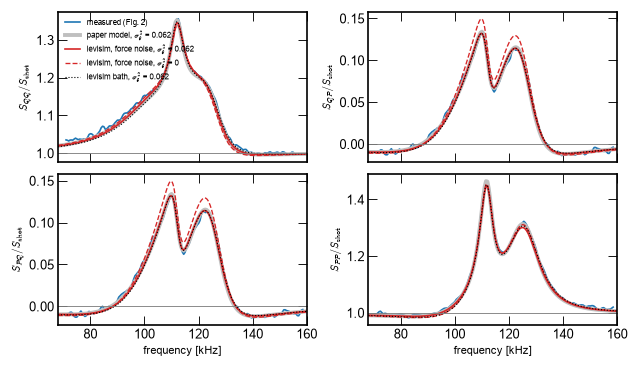

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(8, 4.6), sharex=True)
titles = {'SQQ': r'$S_{QQ}/S_\mathrm{shot}$', 'SQP': r'$S_{QP}/S_\mathrm{shot}$', 'SPQ': r'$S_{PQ}/S_\mathrm{shot}$', 'SPP': r'$S_{PP}/S_\mathrm{shot}$'}
for ax, (panel, index) in zip(axes.flat, PANELS):
    f, v = curve(data['fig2'][panel]['measured'])
    ax.plot(f, v, color='C0', lw=1.5, label='measured (Fig. 2)')
    f, v = curve(data['fig2'][panel]['model_phase_noise'])
    ax.plot(f, v, color='0.75', lw=3.5, label=r'paper model, $\sigma_\theta^2$ = 0.062')
    ax.plot(ω/kHz, detected(S_force, σθ2_PAPER)[index], color='C3', lw=1.5, label=r'levisim, force noise, $\sigma_\theta^2$ = 0.062')
    ax.plot(ω/kHz, detected(S_force)[index], color='C3', lw=1.2, ls='--', label=r'levisim, force noise, $\sigma_\theta^2$ = 0')
    ax.plot(ω/kHz, detected(S_levisim, σθ2_PAPER)[index], color='k', lw=1, ls=':', label=r'levisim bath, $\sigma_\theta^2$ = 0.062')
    ax.axhline(0 if index == 2 else 1, color='grey', lw=0.8)
    ax.set_ylabel(titles[panel])
    ax.set_xlim(ω[0]/kHz, ω[-1]/kHz)
for ax in axes[1]:
    ax.set_xlabel('frequency [kHz]')
axes[0, 0].legend(fontsize=7, frameon=False, loc='upper left')
fig.tight_layout()

## Quadrature spectrum against detection phase and frequency (Fig. 3)

$\tilde S^\phi_Q(\omega)$ from Eq. (2), i.e. `quadrature_spectrum` with $\eta$ = 0.16 and $\sigma_\theta^2$ = 0.062, is shown on the
paper's colour split (red above shot noise, blue below). Fig. 3 is a raster image. Its sub-shot-noise
regions (blue pixels, sampled every 1 kHz, `data['fig3']`) are overlaid as outlines: green squares for the
model map (b), black dots for the measured map (a). The overlap is quantified on the same 1 kHz
columns.

In [ ]:
φ = np.linspace(-π, π, 721)
S_det = detected(S_force)                       # η applied; phase noise inside quadrature_spectrum
S_map = quadrature_spectrum(*S_det, φ[:, None], σθ2=σθ2_PAPER)


def paper_mask(panel, φ_grid):
    columns = data['fig3'][panel]['columns']
    mask = np.zeros((len(φ_grid), len(columns)), dtype=bool)
    for j, column in enumerate(columns):
        for lo, hi in column['sub_shot_phase_intervals_rad']:
            mask[:, j] |= (φ_grid >= lo) & (φ_grid <= hi)
    return np.array([c['frequency_kHz'] for c in columns]), mask


f_cols, mask_b = paper_mask('b', φ)
_, mask_a = paper_mask('a', φ)
S_cols = quadrature_spectrum(*detected(output_quadrature_spectra(mtrap, f_cols*kHz, 'force')), φ[:, None], σθ2=σθ2_PAPER)
ours = S_cols < 1
jaccard = lambda a, b: (a & b).sum() / (a | b).sum()
print(f'sub-shot-noise area, overlap |A∩B|/|A∪B|: levisim vs paper model map (b) {jaccard(ours, mask_b):.2f}, '
      f'vs measured map (a) {jaccard(ours, mask_a):.2f}; paper (b) vs (a) {jaccard(mask_b, mask_a):.2f}')
print(f'fraction of the (φ, ω) plane below shot noise: levisim {ours.mean():.3f}, paper (b) {mask_b.mean():.3f}, measured (a) {mask_a.mean():.3f}')
i, j = np.unravel_index(S_map.argmax(), S_map.shape)
print(f'maximum of the map: {S_map.max():.3f} at {ω[j]/kHz:.1f} kHz, φ = {(φ[i] + π/2) % π - π/2:+.2f} rad modulo π (top of the paper colour scale: 1.52)')
region_phase = {}
for lo, hi in ((68, 105), (130, 160)):
    sel = (ω/kHz >= lo) & (ω/kHz <= hi)
    sub = np.where(φ[:, None] > -π/2 + 0.01, S_map[:, sel], np.inf)[(φ > -π/2) & (φ <= π/2)]
    φ_half = φ[(φ > -π/2) & (φ <= π/2)]
    k, l = np.unravel_index(sub.argmin(), sub.shape)
    region_phase[lo] = φ_half[k]
    band = ω[sel][(S_map[:, sel] < 1).any(axis=0)] / kHz
    print(f'{lo:3d}-{hi} kHz region: minimum {sub.min():.4f} at {ω[sel][l]/kHz:.1f} kHz, φ = {φ_half[k]:+.2f} rad '
          f'(and φ - π); below shot noise from {band.min():.1f} to {band.max():.1f} kHz')
print(f'phase separation of the two minima: {abs(region_phase[68] - region_phase[130]):.2f} rad = '
      f'{abs(region_phase[68] - region_phase[130])/π:.2f} π (PRA: "separated by ≃ π/2")')

sub-shot-noise area, overlap |A∩B|/|A∪B|: levisim vs paper model map (b) 0.90, vs measured map (a) 0.51; paper (b) vs (a) 0.54
fraction of the (φ, ω) plane below shot noise: levisim 0.167, paper (b) 0.151, measured (a) 0.085
maximum of the map: 1.517 at 111.5 kHz, φ = +1.00 rad modulo π (top of the paper colour scale: 1.52)
 68-105 kHz region: minimum 0.9865 at 81.0 kHz, φ = +1.42 rad (and φ - π); below shot noise from 68.0 to 96.2 kHz
130-160 kHz region: minimum 0.9926 at 146.0 kHz, φ = +0.34 rad (and φ - π); below shot noise from 137.0 to 160.0 kHz
phase separation of the two minima: 1.08 rad = 0.34 π (PRA: "separated by ≃ π/2")


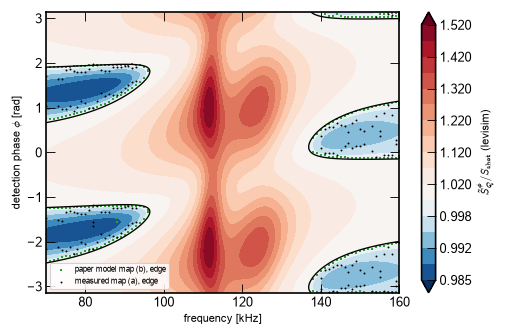

In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
norm = TwoSlopeNorm(vmin=0.985, vcenter=1.0, vmax=1.55)
levels = np.r_[0.985, 0.989, 0.992, 0.995, 0.998, 1.0, np.arange(1.02, 1.56, 0.05)]   # the paper's colour split
mesh = ax.contourf(ω[::2]/kHz, φ[::4], S_map[::4, ::2], levels=levels, cmap='RdBu_r', norm=norm, extend='both')
ax.contour(ω/kHz, φ, S_map, levels=[1.0], colors='k', linewidths=1.2)
for panel, style in (('b', dict(color='C2', s=5, marker='s', lw=0)), ('a', dict(color='k', s=3, marker='o', lw=0))):
    f_c, mask = paper_mask(panel, φ)
    edges = np.diff(mask.astype(int), axis=0) != 0
    ii, jj = np.nonzero(edges)
    ax.scatter(f_c[jj], φ[ii], **style, label='paper model map (b), edge' if panel == 'b' else 'measured map (a), edge')
ax.set_xlabel('frequency [kHz]')
ax.set_ylabel(r'detection phase $\phi$ [rad]')
ax.set_xlim(70, 160)
ax.set_ylim(-π, π)
fig.colorbar(mesh, ax=ax, label=r'$\tilde S^\phi_Q / S_\mathrm{shot}$ (levisim)')
ax.legend(fontsize=7, loc='lower left', framealpha=0.85)
fig.tight_layout()

## Optimal quadrature spectrum (Fig. 4) and the squeezing at higher efficiency

`optimal_quadrature_spectrum` minimises Eq. (2) over $\phi$ at every frequency. As printed, the PRA's Eq. (3)
lacks an overall factor ½; without it the vacuum would give 2. The comparison with the digitised
Fig. 4 is independent of the phase reference.

In [ ]:
S_opt = {}
for noise, S in (('force', S_force), ('levisim', S_levisim)):
    for σθ2 in (0.0, σθ2_PAPER):
        S_opt[noise, σθ2] = optimal_quadrature_spectrum(*with_detection_efficiency(*S, η_HET), σθ2=σθ2)[0]

print(f'{"":42s} {"min S_opt":>9s} {"at [kHz]":>8s} {"max":>6s} {"at [kHz]":>8s} {"rms vs paper":>12s}')
for key, label, σθ2 in (('model_no_phase_noise', 'paper model, σθ² = 0', 0.0), ('model_phase_noise', 'paper model, σθ² = 0.062', σθ2_PAPER),
                        ('measured', 'measured', None)):
    f, v = curve(data['fig4'][key])
    print(f'{label:42s} {v.min():9.4f} {f[v.argmin()]:8.1f} {v.max():6.3f} {f[v.argmax()]:8.1f}')
    if σθ2 is None:
        ours = np.interp(f, ω/kHz, S_opt['force', σθ2_PAPER])
        print(f'{"  levisim, force noise, σθ² = 0.062":42s} {ours.min():9.4f} {f[ours.argmin()]:8.1f} {ours.max():6.3f} {f[ours.argmax()]:8.1f} {rms(ours - v):12.4f}')
        continue
    for noise in ('force', 'levisim'):
        ours = np.interp(f, ω/kHz, S_opt[noise, σθ2])
        print(f'{"  levisim, " + noise + (" noise" if noise == "force" else " bath"):42s} {ours.min():9.4f} {f[ours.argmin()]:8.1f} '
              f'{ours.max():6.3f} {f[ours.argmax()]:8.1f} {rms(ours - v):12.4f}')
f_m, v_m = curve(data['fig4']['measured'])
print(f'\nmeasured S_opt < 1 at: ' + ', '.join(f'{a:.1f}-{b:.1f}' for a, b in
      [(f_m[s], f_m[e - 1]) for s, e in zip(*[np.flatnonzero(np.diff(np.r_[0, (v_m < 1).astype(int), 0]) == d) for d in (1, -1)])] if b - a >= 2) + ' kHz (runs ≥ 2 kHz)')
for σθ2 in (0.0, σθ2_PAPER):
    s = S_opt['force', σθ2]
    band = ω[s < 1]/kHz
    low = band[band < 105]
    print(f'levisim (force noise, σθ² = {σθ2}): S_opt < 1 from {low.min():.1f} to {low.max():.1f} kHz and above {band[band > 105].min():.1f} kHz')
print(f'phase noise changes the deepest squeezing from {1 - S_opt["force", 0.0].min():.2%} to {1 - S_opt["force", σθ2_PAPER].min():.2%} below shot noise')

                                           min S_opt at [kHz]    max at [kHz] rms vs paper
paper model, σθ² = 0                          0.9824     82.5  1.279    112.5
  levisim, force noise                        0.9826     84.5  1.274    112.5       0.0020
  levisim, levisim bath                       0.9793     87.0  1.275    112.5       0.0032
paper model, σθ² = 0.062                      0.9863     79.5  1.292    112.5
  levisim, force noise                        0.9865     81.0  1.287    112.5       0.0021
  levisim, levisim bath                       0.9837     84.0  1.289    112.5       0.0033
measured                                      0.9815     83.0  1.303    112.5
  levisim, force noise, σθ² = 0.062           0.9865     81.0  1.287    112.5       0.0069

measured S_opt < 1 at: 73.0-94.0, 138.5-146.0, 147.0-150.5, 152.0-160.0 kHz (runs ≥ 2 kHz)
levisim (force noise, σθ² = 0.0): S_opt < 1 from 68.0 to 99.5 kHz and above 135.2 kHz
levisim (force noise, σθ² = 0.062): S_opt 

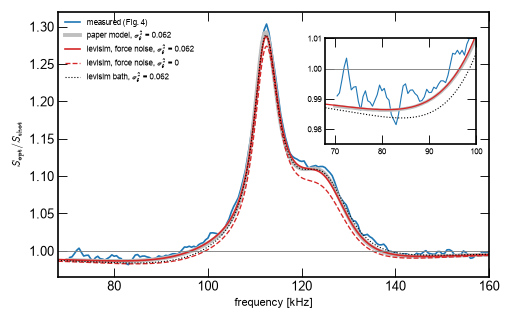

In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 4))
f, v = curve(data['fig4']['measured'])
ax.plot(f, v, color='C0', lw=1.5, label='measured (Fig. 4)')
f, v = curve(data['fig4']['model_phase_noise'])
ax.plot(f, v, color='0.75', lw=3.5, label=r'paper model, $\sigma_\theta^2$ = 0.062')
ax.plot(ω/kHz, S_opt['force', σθ2_PAPER], color='C3', lw=1.5, label=r'levisim, force noise, $\sigma_\theta^2$ = 0.062')
ax.plot(ω/kHz, S_opt['force', 0.0], color='C3', lw=1.2, ls='--', label=r'levisim, force noise, $\sigma_\theta^2$ = 0')
ax.plot(ω/kHz, S_opt['levisim', σθ2_PAPER], color='k', lw=1, ls=':', label=r'levisim bath, $\sigma_\theta^2$ = 0.062')
ax.axhline(1, color='grey', lw=0.8)
ax.set_xlim(ω[0]/kHz, ω[-1]/kHz)
ax.set_xlabel('frequency [kHz]')
ax.set_ylabel(r'$S_\mathrm{opt}/S_\mathrm{shot}$')
ax.legend(fontsize=7, frameon=False, loc='upper left')
inset = ax.inset_axes([0.62, 0.5, 0.35, 0.4])
for key, kw in (('measured', dict(color='C0', lw=1)), ('model_phase_noise', dict(color='0.75', lw=3))):
    f, v = curve(data['fig4'][key])
    inset.plot(f, v, **kw)
inset.plot(ω/kHz, S_opt['force', σθ2_PAPER], color='C3', lw=1.2)
inset.plot(ω/kHz, S_opt['levisim', σθ2_PAPER], color='k', lw=1, ls=':')
inset.axhline(1, color='grey', lw=0.8)
inset.set_xlim(68, 100)
inset.set_ylim(0.975, 1.01)
inset.tick_params(labelsize=7)
fig.tight_layout()

The PRA's discussion projects the squeezing for better detection: removing the factor ½ of the
heterodyne measurement (homodyne at $\eta$ = 0.32) should double it to 4 %, and a single-ended cavity
should double it again to about 8 %. The excess noise scales linearly, $S - 1 \to \eta(S - 1)$, so these
follow from the $\eta$ = 1 spectrum. The last row keeps only the photon recoil computed above
($\rho$ = 1850 kg/m³, inferred waists), the "photon recoil limit" that the paper names as the next step.

In [ ]:
def deepest(S, η, σθ2=0.0):
    s = optimal_quadrature_spectrum(*with_detection_efficiency(*S, η), σθ2=σθ2)[0]
    return s.min(), ω[s.argmin()]/kHz


print(f'{"system":34s} {"η":>5s} {"min S_opt":>10s} {"squeezing":>10s} {"at [kHz]":>9s}')
for η, label in ((0.16, 'heterodyne (paper)'), (0.32, 'homodyne'), (0.64, 'homodyne, single-ended'), (1.0, 'ideal')):
    s, f = deepest(S_force, η)
    print(f'{"fitted Γ, " + label:34s} {η:5.2f} {s:10.4f} {1 - s:10.2%} {f:9.1f}')
m_recoil = pontin_multitrap(Γ_x=RECOIL_1850[0], Γ_y=RECOIL_1850[1])
S_recoil = output_quadrature_spectra(m_recoil, ω, noise='force')
n_recoil = steady_state_covariance_with_noise(m_recoil, 'force')
print(f'recoil only (Γ/2π = {RECOIL_1850[0]/kHz:.2f}, {RECOIL_1850[1]/kHz:.2f} kHz; '
      f'n = {(n_recoil[2, 2] + n_recoil[3, 3] - 2)/4:.2f}, {(n_recoil[4, 4] + n_recoil[5, 5] - 2)/4:.2f}):')
for η in (0.16, 1.0):
    s, f = deepest(S_recoil, η)
    print(f'{"  recoil-limited heating":34s} {η:5.2f} {s:10.4f} {1 - s:10.2%} {f:9.1f}')

system                                 η  min S_opt  squeezing  at [kHz]
fitted Γ, heterodyne (paper)        0.16     0.9826      1.74%      84.2
fitted Γ, homodyne                  0.32     0.9651      3.49%      84.2
fitted Γ, homodyne, single-ended    0.64     0.9303      6.97%      84.2
fitted Γ, ideal                     1.00     0.8910     10.90%      84.2
recoil only (Γ/2π = 1.44, 0.81 kHz; n = 0.20, 0.22):
  recoil-limited heating            0.16     0.9621      3.79%     101.5
  recoil-limited heating            1.00     0.7634     23.66%     101.5


## Summary

All numbers below are printed by the cells above.

**Agreement.**

- **Occupations and state.** With the fitted $g_j$ and $\Gamma_j$ at $\Delta/2\pi$ = −111 kHz, levisim gives
  $n_x$ = 0.551 and $n_y$ = 0.738 with force noise (0.553 and 0.733 with levisim's own bath), against the paper's
  0.55 ± 0.03 and 0.74 ± 0.04. The force-noise mechanical covariance matrix matches Nat. Commun.
  Eq. (4) to within 0.005 in every element, and the purity is 0.209, as published. The system is stable:
  the slowest normal mode decays at about 3 kHz, and the hybridised mechanical modes sit at 112.0 and
  125.8 kHz with linewidths of 6.1 and 15.6 kHz.
- **Heating budget.** The stated 3 × 10⁻⁸ mbar and 250 mW, with waists inferred from the frequencies,
  give 75-100 % of the fitted heating rates. Gas makes up about 55-75 % of the total, which supports
  the PRA's remark that collisions are "a relevant fraction".
- **Spectral covariance matrix (Fig. 2).** levisim's matrix equals `homodyne_spectrum` at every angle
  (10⁻¹⁵). With force noise it equals the PRA's Appendix A closed form (10⁻⁸) once a factor $i$ is removed
  from (A11). Against the digitised paper model curves it agrees to an rms of 0.003 over all four
  panels, in the same quadrature basis (a fitted rotation is 0.01 rad). Fitting $\sigma_\theta^2$ to the digitised
  measured spectra gives 0.058 rad², against the paper's 0.062 rad².
- **Map (Fig. 3).** The two sub-shot-noise regions are reproduced: below the hybridised modes
  (minimum 0.9865 at 81 kHz, $\phi$ = +1.42 rad) and above them (0.993 at 146 kHz, $\phi$ = +0.34 rad). The
  map maximum is 1.517 at 111.5 kHz and $\phi$ = +1.00 rad, against the top of the paper's colour scale
  of 1.52. levisim's sub-shot-noise area overlaps that of the paper's model map (b) 0.90 (intersection
  over union, on the digitised 1 kHz columns). It overlaps the measured map (a) 0.51, about as well as
  the paper's own model does (0.54).
- **Optimal spectrum (Fig. 4).** With $\eta$ = 0.16 levisim's force-noise $S_\mathrm{opt}$ follows the paper's model
  curves to an rms of 0.002. Its minimum is 0.9826 at 84 kHz without phase noise (paper curve: 0.9824)
  and 0.9865 with it (paper 0.9863). It also follows the measured spectrum, with an rms of 0.007. The
  measured minimum is 0.98 at 83 kHz, and the measurement is below shot noise from 73 to 94 kHz;
  levisim's model is below shot noise up to 96 kHz. The projected squeezing for homodyne detection
  (3.5 %) and a single-ended cavity (7.0 %) reproduces the paper's "4 %" and "~8 %". At the recoil limit
  (gas removed) levisim predicts 3.8 % at the paper's $\eta$ = 0.16 and 24 % at $\eta$ = 1, with
  $n_x, n_y \approx$ 0.20, 0.22.

**Differences, and where they come from.**

- **Noise model.** levisim's default bath acts on $b$ and $b^\dagger$, so its diffusion enters position and
  momentum equally. The papers' gas and recoil heating is a pure force noise. The occupations agree
  to 10⁻³, but the off-resonant thermal noise differs, so in the squeezed band levisim's bath predicts
  deeper squeezing (0.979 instead of 0.983 at $\eta$ = 0.16). It also gives a small $x$-$p_x$ correlation
  (−0.03) where force noise gives none. The force-noise model is the physical one for these heating
  mechanisms, and it is what reproduces the paper.
- **Fig. 3 is a raster image**, so its comparison rests on a colour mask (with contour lines merged)
  rather than vector data; the measured map (a) is patchy and overlaps less.

**Inconsistencies in the paper (neutral reading of its own numbers).**

- Eq. (A11) for $A_P$ carries a factor $i$ that the paper's Eq. (A2) does not produce. With it $S_{PP}$ is
  unchanged but $S_{QP}$ is not, and only the version without $i$ reproduces the paper's own Fig. 2
  model curves.
- Eq. (3) lacks an overall factor ½; as printed it gives $S_\mathrm{opt}$ = 2 for the vacuum. Its phase-noise
  variance is written $\sigma_\phi^2$, while Eqs. (1)-(2) use $\sigma_\theta^2$.
- Fig. 3 caption: the two squeezed regions are said to be "separated by ≃ π/2" in phase. The model
  map in Fig. 3(b), and levisim, put their minima about 1.08 rad (0.34π) apart (or 0.66π, modulo π).
- The PRA rounds $\Omega_x/2\pi$ to 121 kHz, following the Nat. Commun. text (121.1 kHz). The Nat. Commun.
  fit (Table 1), which also sets the published couplings, gives 122.17 kHz; this notebook uses the
  fit values.
- "Phase noise has a negligible effect" in the squeezed regions: in the model it reduces the deepest
  squeezing from 1.74 % to 1.35 % below shot noise. That is small in absolute terms but a fifth of
  the effect.
- The detuning is not stated in the PRA; −111 kHz comes from the companion Nat. Commun. data set,
  which the PRA says it reanalyses. It reproduces every figure.

In [ ]:
print(f'notebook runtime: {time.time() - T_START:.1f} s')

notebook runtime: 0.5 s
